# From Words to Worlds · Milestone 2 · Exp 3: the stress-prompt benchmark

**Praniti Kale** · IE 7615 Deep Learning for AI · Generative project · continues `milestone-1/exp3`

Milestone 1 built 200 **stress prompts**: short prompts that each test one skill text-to-image models are known to get wrong, stored with their expected answer. This notebook **runs that exam** on Stable Diffusion 1.5 and scores every image automatically, then repeats it across guidance scales and noise schedules.

| Milestone 2 requirement | Where |
|---|---|
| 1. Integrate a text encoder with a diffusion model | Stable Diffusion 1.5 conditioned by its CLIP ViT-L/14 text encoder (the Milestone 1 pipeline, verified pixel-exact there) |
| 2. Run baseline conditional generation | Section 4: all 200 prompts × 3 seeds at the default settings |
| 3. Tune classifier-free guidance + noise schedule (≥ 3 values each) | Section 5: guidance {3, 7.5, 12} × scheduler {DDIM, PNDM, DPM++} |
| 4. Record the first set of generated images | Every image saved with a **generation log** (prompt, seed, settings, time) |
| Submission: training / generation log, 5–10 samples, 1-page summary | Sections 9–10: `generation_log.csv`, sample images with prompts, numbers for the summary |

**The five skills** (40 prompts each):

| Family | Example | Scored automatically by |
|---|---|---|
| Multi-object | "a horse, a bus and a bottle" | all three objects detected |
| Counting | "three zebras" | detected count equals the number asked for (and "off by one") |
| Colour binding | "a yellow book and a white truck" | each object cropped and its colour read by CLIP: right, swapped, or other |
| Spatial | "a bowl to the left of a zebra" | box positions of the two objects |
| Word order | "a bear following a sheep" / "a sheep following a bear" | each image matches its own sentence better than its swapped twin (chance 50%) |

It also finishes two Milestone 1 loose ends: the **real reference set** is redrawn to be disjoint from the dev set (Section 2), and the **text-encoder comparison** gets 95% intervals and a word-order test that measures meaning rather than sentence structure (Section 11).


In [1]:
%pip install -q -U diffusers transformers accelerate safetensors sentencepiece scikit-learn

## 1. Setup

In [2]:
import os, sys, re, json, time, random, zipfile, textwrap, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CFG = dict(
    # data (the Milestone 1 rules and seeds)
    seed_eval=2026, seed_dev=2027, seed_ref=2028, seed_stress=2030, min_short_side=256,
    n_eval=2000, n_dev=500, n_ref=2000,
    # model
    sd_id="stable-diffusion-v1-5/stable-diffusion-v1-5", clip_id="openai/clip-vit-large-patch14", steps=30,
    # baseline (Stable Diffusion's defaults)
    base_guidance=7.5, base_scheduler="pndm", base_seeds=(0, 1, 2),
    # sweep: at least 3 values of each (match the COCO sweeps)
    sweep_guidance=(3.0, 7.5, 12.0), sweep_schedulers=("ddim", "pndm", "dpmpp"), sweep_seed=0,
    sweep_per_family=None,          # None = all 40 prompts per family; 20 halves the sweep
    # scoring
    det_min_score=0.5,              # detector confidence threshold
    spatial_margin=0.05,            # boxes must be this share of the image apart for left/right/above/below
    # sections
    run_split_fix=True, run_baseline=True, run_sweep=True, run_encoder_polish=True,
)

IN_COLAB = "google.colab" in sys.modules
if "W2W_ROOT" in os.environ:
    DATA = RESULTS_ROOT = Path(os.environ["W2W_ROOT"])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA, RESULTS_ROOT = Path("/content/w2w_data"), Path("/content/drive/MyDrive/w2w_praniti")
else:
    DATA = RESULTS_ROOT = Path.cwd() / "w2w_praniti"
COCO, ANN_DIR = DATA / "coco", DATA / "coco" / "annotations"
M1 = RESULTS_ROOT / "results"                      # Milestone 1 outputs, if on Drive
OUT = RESULTS_ROOT / "results" / "m2_exp3"
FIGS, GEN, SAMPLES = OUT / "figures", RESULTS_ROOT / "runs" / "m2_stress", OUT / "samples"
for p in (ANN_DIR, OUT, FIGS, GEN, SAMPLES, OUT / "splits"):
    p.mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(OUT / "config.json", "w"), indent=2)


def savefig(name):
    plt.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=140)


def bootstrap_ci(values, n=5000, seed=0):
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    if len(v) == 0:
        return {"mean": float("nan"), "lo": float("nan"), "hi": float("nan"), "n": 0}
    m = np.random.default_rng(seed).choice(v, (n, len(v)), replace=True).mean(1)
    return {"mean": float(v.mean()), "lo": float(np.percentile(m, 2.5)), "hi": float(np.percentile(m, 97.5)), "n": int(len(v))}


print("results:", OUT, "| images:", GEN)

Mounted at /content/drive
results: /content/drive/MyDrive/w2w_praniti/results/m2_exp3 | images: /content/drive/MyDrive/w2w_praniti/runs/m2_stress


## 2. The splits, and a fully disjoint reference set

The COCO annotations are downloaded and the Milestone 1 test and dev splits rebuilt with the same rules and seeds (and checked against the saved files on Drive). In Milestone 1 the 2,000-photo real reference set was drawn only from photos outside the test split, so it shared 353 photos with the dev split, while the proposal describes three **disjoint** sets. It is redrawn here from photos outside **both** test and dev (same seed, 2028). The test and dev splits do not change. The new file is `real_ref_2000_disjoint.csv`; the old one is kept untouched.

In [3]:
def download(url, dest):
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    tmp = dest.with_suffix(dest.suffix + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f, tqdm(total=int(r.headers.get("content-length", 0)), unit="B", unit_scale=True, desc=dest.name) as bar:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk); bar.update(len(chunk))
    tmp.rename(dest)
    return dest


if not (ANN_DIR / "captions_val2017.json").exists() or not (ANN_DIR / "instances_val2017.json").exists():
    with zipfile.ZipFile(download("http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
                                  COCO / "annotations_trainval2017.zip")) as z:
        z.extractall(COCO, [m for m in z.namelist() if m.endswith(("captions_val2017.json", "instances_val2017.json"))])
caps_json = json.load(open(ANN_DIR / "captions_val2017.json", encoding="utf-8"))
inst_json = json.load(open(ANN_DIR / "instances_val2017.json", encoding="utf-8"))

_WS = re.compile(r"\s+")


def clean_caption(text):
    t = _WS.sub(" ", text.replace("\n", " ")).strip()
    return re.sub(r"\s+([.,!?;:])", r"\1", t)


by_image = defaultdict(list)
for a in caps_json["annotations"]:
    by_image[a["image_id"]].append(a["caption"])
rows = []
for im in sorted(caps_json["images"], key=lambda d: d["id"]):
    seen = set()
    for c in by_image.get(im["id"], []):
        cc = clean_caption(c)
        if cc and cc.lower() not in seen:
            seen.add(cc.lower()); rows.append({"image_id": im["id"], "caption": cc})
caps = pd.DataFrame(rows)
caps.insert(0, "caption_idx", range(len(caps)))
images = pd.DataFrame(caps_json["images"]).rename(columns={"id": "image_id"}).set_index("image_id")
eligible = sorted(i for i, r in images.iterrows() if min(r.width, r.height) >= CFG["min_short_side"])


def draw_pairs(pool, n, seed):
    rng = random.Random(seed)
    out = []
    for iid in rng.sample(sorted(pool), n):
        ci = rng.choice(caps.loc[caps.image_id == iid, "caption_idx"].tolist())
        out.append({"image_id": iid, "caption_idx": ci, "caption": caps.loc[caps.caption_idx == ci, "caption"].item()})
    return pd.DataFrame(out)


ev = draw_pairs(eligible, CFG["n_eval"], CFG["seed_eval"])
dev = draw_pairs(set(eligible) - set(ev.image_id), CFG["n_dev"], CFG["seed_dev"])
for name, frame in (("eval_2000", ev), ("dev_500", dev)):
    saved = M1 / "splits" / f"{name}.csv"
    if saved.exists():
        old = pd.read_csv(saved)
        assert old.image_id.tolist() == frame.image_id.tolist() and old.caption_idx.tolist() == frame.caption_idx.tolist(), name
        print(f"{name}: matches the Milestone 1 file")

if CFG["run_split_fix"]:
    pool = sorted(set(eligible) - set(ev.image_id) - set(dev.image_id))
    ref = pd.DataFrame({"image_id": sorted(random.Random(CFG["seed_ref"]).sample(pool, CFG["n_ref"]))})
    e, d, b = set(ev.image_id), set(dev.image_id), set(ref.image_id)
    assert not (e & d) and not (e & b) and not (d & b), "the three sets must be disjoint"
    ref.to_csv(OUT / "splits" / "real_ref_2000_disjoint.csv", index=False, lineterminator="\n")
    old_ref = M1 / "splits" / "real_ref_b_2000.csv"
    old_overlap = len(set(pd.read_csv(old_ref).image_id) & d) if old_ref.exists() else None
    split_fix = {"eligible": len(eligible), "test": len(e), "dev": len(d), "reference": len(b),
                 "test_dev": 0, "test_ref": 0, "dev_ref": 0, "old_reference_dev_overlap": old_overlap,
                 "file": str(OUT / "splits" / "real_ref_2000_disjoint.csv")}
    print(json.dumps(split_fix, indent=2))

annotations_trainval2017.zip:   0%|          | 0.00/253M [00:00<?, ?B/s]

eval_2000: matches the Milestone 1 file
dev_500: matches the Milestone 1 file
{
  "eligible": 4958,
  "test": 2000,
  "dev": 500,
  "reference": 2000,
  "test_dev": 0,
  "test_ref": 0,
  "dev_ref": 0,
  "old_reference_dev_overlap": 353,
  "file": "/content/drive/MyDrive/w2w_praniti/results/m2_exp3/splits/real_ref_2000_disjoint.csv"
}


## 3. The 200 stress prompts

Loaded from the Milestone 1 results on Drive if present; otherwise rebuilt with the same random draws (seed 2030), and the two are checked to match.

In [4]:
ANIMALS = ["dog", "cat", "horse", "cow", "sheep", "bird", "elephant", "giraffe", "zebra", "bear"]
THINGS = ["car", "bus", "truck", "bicycle", "boat", "chair", "bench", "umbrella", "clock", "vase",
          "cup", "bowl", "bottle", "book", "laptop", "suitcase", "backpack", "pizza", "cake", "apple"]
COLOURS = ["red", "blue", "green", "yellow", "black", "white", "purple", "orange"]
NUMBERS = {2: "two", 3: "three", 4: "four", 5: "five"}
PLURAL = {"bus": "buses", "sheep": "sheep", "bench": "benches"}
VERBS = ["chasing", "looking at", "standing next to", "following", "sitting behind"]
SPATIAL = [("to the left of", "left"), ("to the right of", "right"), ("on top of", "above"), ("below", "below")]
SCENES = ["in a park", "in a field", "on a grassy hill", "in a backyard", "on a dirt road"]
FAMILIES = ["multi_object", "counting", "colour_binding", "spatial", "word_order"]
FAMILY_LABEL = {"multi_object": "Multi-object", "counting": "Counting", "colour_binding": "Colour binding",
                "spatial": "Spatial", "word_order": "Word order"}


def article(w):
    return "an" if w[0] in "aeiou" else "a"


def build_stress(seed):
    rng, rows = random.Random(seed), []

    def add(family, prompt, objects, expected, pair_id=""):
        k = sum(r["family"] == family for r in rows)
        rows.append({"prompt_id": f"{family}_{k:02d}", "family": family, "prompt": prompt,
                     "objects": json.dumps(objects), "expected": json.dumps(expected), "pair_id": pair_id})

    def count(f):
        return sum(r["family"] == f for r in rows)

    pairs = set()
    while len(pairs) < 20:
        a, b = rng.sample(ANIMALS, 2)
        pairs.add((a, b, rng.choice(VERBS), rng.choice(SCENES)))
    for k, (a, b, v, s) in enumerate(sorted(pairs)):
        for x, y in ((a, b), (b, a)):
            add("word_order", f"{article(x)} {x} {v} {article(y)} {y} {s}", [x, y], {"subject": x, "object": y, "verb": v}, f"wo{k:02d}")
    seen = set()
    while count("counting") < 40:
        o, n = rng.choice(ANIMALS + THINGS), rng.choice(list(NUMBERS))
        if (o, n) not in seen:
            seen.add((o, n)); add("counting", f"{NUMBERS[n]} {PLURAL.get(o, o + 's')}", [o], {"count": {o: n}})
    seen = set()
    while count("colour_binding") < 40:
        a, b = rng.sample(THINGS, 2); ca, cb = rng.sample(COLOURS, 2)
        if (a, b, ca, cb) not in seen:
            seen.add((a, b, ca, cb))
            add("colour_binding", f"{article(ca)} {ca} {a} and {article(cb)} {cb} {b}", [a, b], {"colour": {a: ca, b: cb}})
    seen = set()
    while count("spatial") < 40:
        a, b = rng.sample(ANIMALS + THINGS, 2); phrase, rel = rng.choice(SPATIAL)
        if (a, b, rel) not in seen:
            seen.add((a, b, rel)); add("spatial", f"{article(a)} {a} {phrase} {article(b)} {b}", [a, b], {"relation": rel, "first": a, "second": b})
    seen = set()
    while count("multi_object") < 40:
        objs = tuple(sorted(rng.sample(ANIMALS + THINGS, 3)))
        if objs not in seen:
            seen.add(objs); a, b, c = rng.sample(objs, 3)
            add("multi_object", f"{article(a)} {a}, {article(b)} {b} and {article(c)} {c}", [a, b, c], {"present": [a, b, c]})
    return pd.DataFrame(rows)


stress = build_stress(CFG["seed_stress"])
saved = M1 / "stress_prompts.csv"
if saved.exists():
    assert pd.read_csv(saved).prompt.tolist() == stress.prompt.tolist(), "stress prompts differ from Milestone 1"
    print("stress prompts match the Milestone 1 file")
stress["objects_l"] = stress.objects.map(json.loads)
stress["expected_d"] = stress.expected.map(json.loads)
assert len(stress) == 200 and stress.family.value_counts().eq(40).all()


def sweep_prompts():
    if CFG["sweep_per_family"] is None:
        return stress
    keep = []
    for f in FAMILIES:
        g = stress[stress.family == f]
        if f == "word_order":                                 # keep whole pairs
            pids = sorted(g.pair_id.unique())[: CFG["sweep_per_family"] // 2]
            keep.append(g[g.pair_id.isin(pids)])
        else:
            keep.append(g.head(CFG["sweep_per_family"]))
    return pd.concat(keep)


print(stress.family.value_counts().to_dict())
stress.groupby("family").head(1)[["prompt_id", "family", "prompt", "expected"]]

stress prompts match the Milestone 1 file
{'word_order': 40, 'counting': 40, 'colour_binding': 40, 'spatial': 40, 'multi_object': 40}


,prompt_id,family,prompt,expected
0,word_order_00,word_order,a bear following a sheep on a grassy hill,"{""subject"": ""bear"", ""object"": ""sheep"", ""verb"":..."
40,counting_00,counting,four boats,"{""count"": {""boat"": 4}}"
80,colour_binding_00,colour_binding,a yellow book and a white truck,"{""colour"": {""book"": ""yellow"", ""truck"": ""white""}}"
120,spatial_00,spatial,a bowl to the left of a zebra,"{""relation"": ""left"", ""first"": ""bowl"", ""second""..."
160,multi_object_00,multi_object,"a horse, a bus and a bottle","{""present"": [""horse"", ""bus"", ""bottle""]}"


## 4. Generation: the baseline

Stable Diffusion 1.5 with its CLIP ViT-L/14 text encoder, 30 steps. Every image is saved as `runs/m2_stress/<setting>/<prompt_id>_s<seed>.png` and logged with its prompt, seed, guidance, scheduler, steps and the seconds it took (measured after a warm-up, on the same GPU). Images the safety checker blacks out are flagged and left out of all scores. Images already on Drive are reused.

**Baseline:** PNDM (Stable Diffusion's default scheduler), guidance 7.5, seeds 0, 1 and 2, all 200 prompts.

In [5]:
import torch
import torch.nn.functional as F
from diffusers import StableDiffusionPipeline, PNDMScheduler, DDIMScheduler, DPMSolverMultistepScheduler

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
assert DEVICE == "cuda", "This notebook needs a GPU (Colab: Runtime -> Change runtime type -> T4 GPU)"
GPU = torch.cuda.get_device_name(0)
print(torch.__version__, GPU)

pipe = StableDiffusionPipeline.from_pretrained(CFG["sd_id"], torch_dtype=DTYPE).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
BASE_SCHED = pipe.scheduler.config
SCHEDULERS = {"pndm": PNDMScheduler, "ddim": DDIMScheduler, "dpmpp": DPMSolverMultistepScheduler}
LOG_FILE = OUT / "generation_log.csv"
LOG = pd.read_csv(LOG_FILE).to_dict("records") if LOG_FILE.exists() else []
_logged = {(r["setting"], r["prompt_id"], int(r["seed"])) for r in LOG}


def setting_name(scheduler, guidance):
    return f"{scheduler}_g{guidance:g}_st{CFG['steps']}"


@torch.no_grad()
def paint(prompt, seed, guidance):
    g = torch.Generator(DEVICE).manual_seed(int(seed))
    torch.cuda.synchronize(); t0 = time.perf_counter()
    img = pipe(prompt, num_inference_steps=CFG["steps"], guidance_scale=guidance, generator=g).images[0]
    torch.cuda.synchronize()
    return img, time.perf_counter() - t0


def run_setting(prompts, seeds, scheduler, guidance):
    name = setting_name(scheduler, guidance)
    out_dir = GEN / name
    out_dir.mkdir(parents=True, exist_ok=True)
    pipe.scheduler = SCHEDULERS[scheduler].from_config(BASE_SCHED)
    paint("warm-up", 0, guidance)                               # untimed
    todo = [(r, s) for r in prompts.itertuples() for s in seeds]
    new = 0
    for r, s in tqdm(todo, desc=name):
        path = out_dir / f"{r.prompt_id}_s{s}.png"
        if (name, r.prompt_id, s) in _logged and path.exists():
            continue
        if path.exists():
            img, dt = Image.open(path).convert("RGB"), float("nan")
        else:
            img, dt = paint(r.prompt, s, guidance)
            img.save(path); new += 1
        black = bool(np.asarray(img.convert("L")).max() < 10)
        LOG.append({"setting": name, "prompt_id": r.prompt_id, "family": r.family, "prompt": r.prompt, "seed": int(s),
                    "guidance": guidance, "scheduler": scheduler, "steps": CFG["steps"], "seconds": round(dt, 3),
                    "blacked_out": black, "path": str(path), "gpu": GPU, "time": time.strftime("%Y-%m-%d %H:%M:%S")})
        _logged.add((name, r.prompt_id, s))
        if len(LOG) % 50 == 0:
            pd.DataFrame(LOG).to_csv(LOG_FILE, index=False)
    pd.DataFrame(LOG).to_csv(LOG_FILE, index=False)
    print(f"{name}: {new} new images, {len(todo) - new} already on disk")
    return name


BASE = setting_name(CFG["base_scheduler"], CFG["base_guidance"])
if CFG["run_baseline"]:
    run_setting(stress, CFG["base_seeds"], CFG["base_scheduler"], CFG["base_guidance"])

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.


2.14.1+cu130 Tesla T4


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

pndm_g7.5_st30:   0%|          | 0/600 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


pndm_g7.5_st30: 600 new images, 0 already on disk


## 5. Generation: the guidance × noise-schedule sweep

Classifier-free guidance at **3, 7.5 and 12** (how hard the model is pushed toward the prompt) crossed with three noise schedules / samplers, **DDIM, PNDM and DPM++** (how the noise is removed step by step), all at 30 steps, seed 0. The PNDM / 7.5 setting reuses the baseline's seed-0 images. Settings and values can be changed in Section 1 to match the group's COCO sweeps.

In [6]:
SWEEP = []
if CFG["run_sweep"]:
    sp = sweep_prompts()
    print(f"sweep: {len(sp)} prompts x {len(CFG['sweep_guidance']) * len(CFG['sweep_schedulers'])} settings")
    for sch in CFG["sweep_schedulers"]:
        for g in CFG["sweep_guidance"]:
            SWEEP.append(run_setting(sp, (CFG["sweep_seed"],), sch, g))
del pipe
torch.cuda.empty_cache()
gen_log = pd.DataFrame(LOG)
print(gen_log.groupby("setting").agg(images=("prompt_id", "size"), seconds_per_image=("seconds", "mean"),
                                     blacked_out=("blacked_out", "sum")).round(2))

sweep: 200 prompts x 9 settings


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim_g3_st30:   0%|          | 0/200 [00:00<?, ?it/s]

ddim_g3_st30: 200 new images, 0 already on disk


ddim_g7.5_st30:   0%|          | 0/200 [00:00<?, ?it/s]

ddim_g7.5_st30: 200 new images, 0 already on disk


... (12 outputs left out)

dpmpp_g7.5_st30:   0%|          | 0/200 [00:00<?, ?it/s]

dpmpp_g7.5_st30: 200 new images, 0 already on disk


dpmpp_g12_st30:   0%|          | 0/200 [00:00<?, ?it/s]

dpmpp_g12_st30: 200 new images, 0 already on disk
                 images  seconds_per_image  blacked_out
setting                                                
ddim_g12_st30       200               5.08            0
ddim_g3_st30        200               5.09            0
ddim_g7.5_st30      200               5.09            0
dpmpp_g12_st30      200               5.05            0
dpmpp_g3_st30       200               5.04            0
dpmpp_g7.5_st30     200               5.04            0
pndm_g12_st30       200               5.24            1
pndm_g3_st30        200               5.23            1
pndm_g7.5_st30      600               5.22            4


## 6. The judges

* **Objects and counts:** torchvision's Faster R-CNN (ResNet-50 FPN v2, COCO classes), confidence ≥ 0.5. Every stress-prompt object is a COCO class. To use the group's calibrated judges instead, change `det_min_score` or swap the detector here.
* **Colours:** each object's highest-scoring box is cropped and CLIP ViT-L/14 chooses among the 8 colours ("a photo of a red car", …).
* **Word order:** CLIP compares each image with its own sentence and with the swapped twin; the image passes if it matches its own sentence better. CLIP itself is partly blind to word order, so this judge is lenient; the number is a lower bound on how often the model is wrong.

The scoring rules are plain functions, checked on hand-made detections before use.

In [7]:
def found(dets, name):
    return [d for d in dets if d["label"] == name]


def score_multi(dets, objects):
    k = sum(bool(found(dets, o)) for o in objects)
    return {"pass": float(k == len(objects)), "objects_found": k / len(objects)}


def score_count(dets, obj, n):
    c = len(found(dets, obj))
    return {"pass": float(c == n), "off_by_one": float(abs(c - n) <= 1), "present": float(c > 0), "counted": c}


def best_box(dets, name):
    f = found(dets, name)
    return max(f, key=lambda d: d["score"])["box"] if f else None


def score_spatial(dets, first, second, relation, size=512, margin=CFG["spatial_margin"]):
    a, b = best_box(dets, first), best_box(dets, second)
    if a is None or b is None:
        return {"pass": 0.0, "both_present": 0.0}
    (ax, ay), (bx, by) = ((a[0] + a[2]) / 2, (a[1] + a[3]) / 2), ((b[0] + b[2]) / 2, (b[1] + b[3]) / 2)
    m = margin * size
    ok = {"left": ax < bx - m, "right": ax > bx + m, "above": ay < by - m, "below": ay > by + m}[relation]
    return {"pass": float(ok), "both_present": 1.0}


def colour_verdict(pred_a, pred_b, exp_a, exp_b):
    if pred_a is None or pred_b is None:
        return "missing"
    if pred_a == exp_a and pred_b == exp_b:
        return "correct"
    if pred_a == exp_b and pred_b == exp_a:
        return "swapped"
    return "other"


# checks on hand-made detections
D = [{"label": "dog", "score": .9, "box": [10, 200, 110, 300]}, {"label": "cat", "score": .8, "box": [300, 210, 400, 310]},
     {"label": "dog", "score": .7, "box": [150, 200, 220, 300]}]
assert score_multi(D, ["dog", "cat", "bus"])["pass"] == 0 and score_multi(D, ["dog", "cat"])["pass"] == 1
assert score_count(D, "dog", 2)["pass"] == 1 and score_count(D, "dog", 3)["off_by_one"] == 1
assert score_spatial(D, "dog", "cat", "left")["pass"] == 1 and score_spatial(D, "dog", "cat", "right")["pass"] == 0
assert score_spatial(D, "dog", "bus", "left")["both_present"] == 0
assert colour_verdict("red", "blue", "red", "blue") == "correct" and colour_verdict("blue", "red", "red", "blue") == "swapped"
print("scoring rules: all checks passed")

scoring rules: all checks passed


In [8]:
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2
from transformers import CLIPModel, CLIPProcessor

W = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
detector = fasterrcnn_resnet50_fpn_v2(weights=W).eval().to(DEVICE)
DET_NAMES = W.meta["categories"]
clip_model = CLIPModel.from_pretrained(CFG["clip_id"], torch_dtype=DTYPE).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CFG["clip_id"])


@torch.no_grad()
def detect(img):
    x = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255).permute(2, 0, 1)
    r = detector([x.to(DEVICE)])[0]
    return [{"label": DET_NAMES[l], "score": float(s), "box": [float(v) for v in b]}
            for l, s, b in zip(r["labels"].tolist(), r["scores"].tolist(), r["boxes"].tolist()) if s >= CFG["det_min_score"]]


@torch.no_grad()
def clip_image(imgs):
    px = clip_proc.image_processor(images=imgs, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
    return F.normalize(clip_model.visual_projection(clip_model.vision_model(pixel_values=px).pooler_output).float(), dim=-1)


@torch.no_grad()
def clip_text(texts):
    tok = clip_proc.tokenizer(list(texts), padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(DEVICE)
    return F.normalize(clip_model.text_projection(clip_model.text_model(input_ids=tok.input_ids).pooler_output).float(), dim=-1)


def crop_colour(img, box, obj):
    x0, y0, x1, y1 = box
    pad = 0.1 * max(x1 - x0, y1 - y0)
    crop = img.crop((max(0, x0 - pad), max(0, y0 - pad), min(img.width, x1 + pad), min(img.height, y1 + pad)))
    sims = (clip_image([crop]) @ clip_text([f"a photo of a {c} {obj}" for c in COLOURS]).T)[0]
    return COLOURS[int(sims.argmax())]


def score_image(row, img, dets):
    p = stress.loc[stress.prompt_id == row.prompt_id].iloc[0]
    ex, objs = p.expected_d, p.objects_l
    if p.family == "multi_object":
        return score_multi(dets, objs)
    if p.family == "counting":
        (obj, n), = ex["count"].items()
        return score_count(dets, obj, n)
    if p.family == "spatial":
        return score_spatial(dets, ex["first"], ex["second"], ex["relation"], size=img.width)
    if p.family == "colour_binding":
        a, b = objs
        ba, bb = best_box(dets, a), best_box(dets, b)
        pa = crop_colour(img, ba, a) if ba else None
        pb = crop_colour(img, bb, b) if bb else None
        v = colour_verdict(pa, pb, ex["colour"][a], ex["colour"][b])
        return {"pass": float(v == "correct"), "swapped": float(v == "swapped"), "both_present": float(v != "missing"),
                "verdict": v, "colours_seen": f"{pa}/{pb}"}
    if p.family == "word_order":
        return {"pass": np.nan, "both_present": float(bool(found(dets, objs[0])) and bool(found(dets, objs[1])))}
    raise ValueError(p.family)


SCORES_FILE = OUT / "scores.csv"
done = pd.read_csv(SCORES_FILE) if SCORES_FILE.exists() else pd.DataFrame(columns=["setting", "prompt_id", "seed"])
done_keys = set(zip(done.setting, done.prompt_id, done.seed.astype(int)))
rows = done.to_dict("records")
todo = gen_log[~gen_log.blacked_out & ~gen_log.apply(lambda r: (r.setting, r.prompt_id, int(r.seed)) in done_keys, axis=1)]
for r in tqdm(todo.itertuples(), total=len(todo), desc="scoring"):
    img = Image.open(r.path).convert("RGB")
    s = score_image(r, img, detect(img))
    rows.append({"setting": r.setting, "prompt_id": r.prompt_id, "family": r.family, "seed": int(r.seed),
                 "guidance": r.guidance, "scheduler": r.scheduler, **s})
scores = pd.DataFrame(rows)

# word order: each image against its own sentence and its swapped twin (needs both images of a pair)
twin = {}
for pid, g in stress[stress.family == "word_order"].groupby("pair_id"):
    a, b = g.prompt_id.tolist()
    twin[a], twin[b] = b, a
wo = gen_log[(gen_log.family == "word_order") & ~gen_log.blacked_out]
paths = {(r.setting, r.prompt_id, int(r.seed)): r.path for r in wo.itertuples()}
for i, r in scores[scores.family == "word_order"].iterrows():
    own = stress.loc[stress.prompt_id == r.prompt_id, "prompt"].item()
    other = stress.loc[stress.prompt_id == twin[r.prompt_id], "prompt"].item()
    f_img = clip_image([Image.open(paths[(r.setting, r.prompt_id, int(r.seed))]).convert("RGB")])
    sims = (f_img @ clip_text([own, other]).T)[0]
    scores.loc[i, "pass"] = float(sims[0] > sims[1])
    scores.loc[i, "margin"] = float(sims[0] - sims[1])
scores.to_csv(SCORES_FILE, index=False)
print(f"{len(scores)} images scored ({int(gen_log.blacked_out.sum())} blacked-out images left out)")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 154MB/s]


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

scoring:   0%|          | 0/2194 [00:00<?, ?it/s]

2194 images scored (6 blacked-out images left out)


## 7. Baseline results: which skills does Stable Diffusion get right?

Pass rate per family at the default settings, averaged over the three seeds for each prompt, with a 95% bootstrap interval over prompts.

,pass rate,ci_lo,ci_hi,prompts,objects_found,off_by_one,present,both_present,swapped
Multi-object,0.129,0.067,0.204,40.0,0.593,NaN,NaN,NaN,NaN
Counting,0.292,0.208,0.383,40.0,NaN,0.642,0.983,NaN,NaN
Colour binding,0.033,0.008,0.067,40.0,NaN,NaN,NaN,0.250,0.05
Spatial,0.208,0.133,0.292,40.0,NaN,NaN,NaN,0.442,NaN
Word order,0.525,0.392,0.650,40.0,NaN,NaN,NaN,0.250,NaN


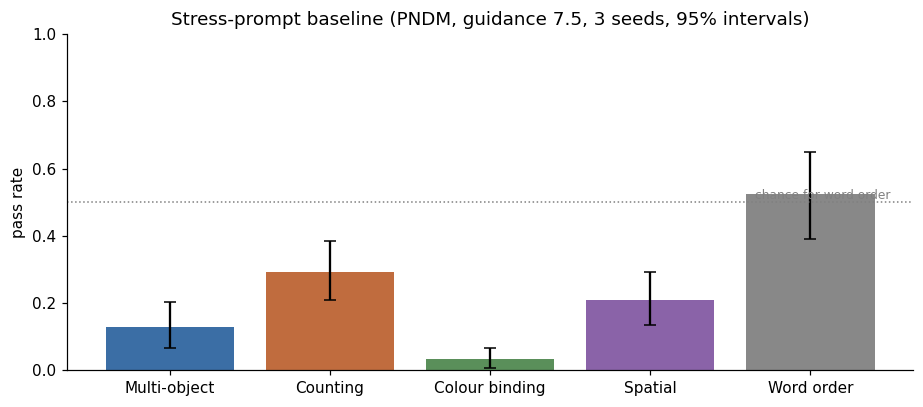

counting: right number 29%, off by at most one 64%, object present at all 98%
colour binding verdicts: missing 75%, other 17%, swapped 5%, correct 3%


In [9]:
def family_table(df, extra=()):
    extra = [e for e in extra if e in df.columns]
    per_prompt = df.groupby(["family", "prompt_id"])[["pass", *extra]].apply(lambda g: g.astype(float).mean())
    out = {}
    for f in FAMILIES:
        if f not in per_prompt.index.get_level_values(0):
            continue
        sub = per_prompt.loc[f]
        ci = bootstrap_ci(sub["pass"].values)
        row = {"pass rate": ci["mean"], "ci_lo": ci["lo"], "ci_hi": ci["hi"], "prompts": ci["n"]}
        for e in extra:
            if e in sub and sub[e].notna().any():
                row[e] = float(sub[e].mean())
        out[FAMILY_LABEL[f]] = row
    return pd.DataFrame(out).T


base_scores = scores[scores.setting == BASE]
base_table = family_table(base_scores, extra=("both_present", "objects_found", "off_by_one", "present", "swapped"))
base_table.to_csv(OUT / "baseline_by_family.csv")
display(base_table.round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = base_table["pass rate"].values
ax.bar(base_table.index, y, yerr=[y - base_table.ci_lo, base_table.ci_hi - y], capsize=4,
       color=["#3b6ea5", "#c06c3e", "#5a8f5a", "#8a63a8", "#888888"][:len(y)])
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.text(len(y) - 0.5, 0.51, "chance for word order", fontsize=8, ha="right", color="gray")
ax.set(ylim=(0, 1), ylabel="pass rate", title=f"Stress-prompt baseline (PNDM, guidance {CFG['base_guidance']}, 3 seeds, 95% intervals)")
plt.tight_layout(); savefig("01_baseline_by_family"); plt.show()

extra_lines = []
if "Counting" in base_table.index:
    cnt = base_scores[base_scores.family == "counting"]
    extra_lines.append(f"counting: right number {cnt['pass'].mean():.0%}, off by at most one {cnt['off_by_one'].mean():.0%}, "
                       f"object present at all {cnt['present'].mean():.0%}")
if "Colour binding" in base_table.index:
    col = base_scores[base_scores.family == "colour_binding"].verdict.value_counts(normalize=True)
    extra_lines.append("colour binding verdicts: " + ", ".join(f"{k} {v:.0%}" for k, v in col.items()))
print("\n".join(extra_lines))

## 8. Sweep results: guidance × noise schedule

The same pass rates for every setting (seed 0), and the seconds per image for each scheduler. Settings are compared on the same prompts and seed, so differences come from the setting.

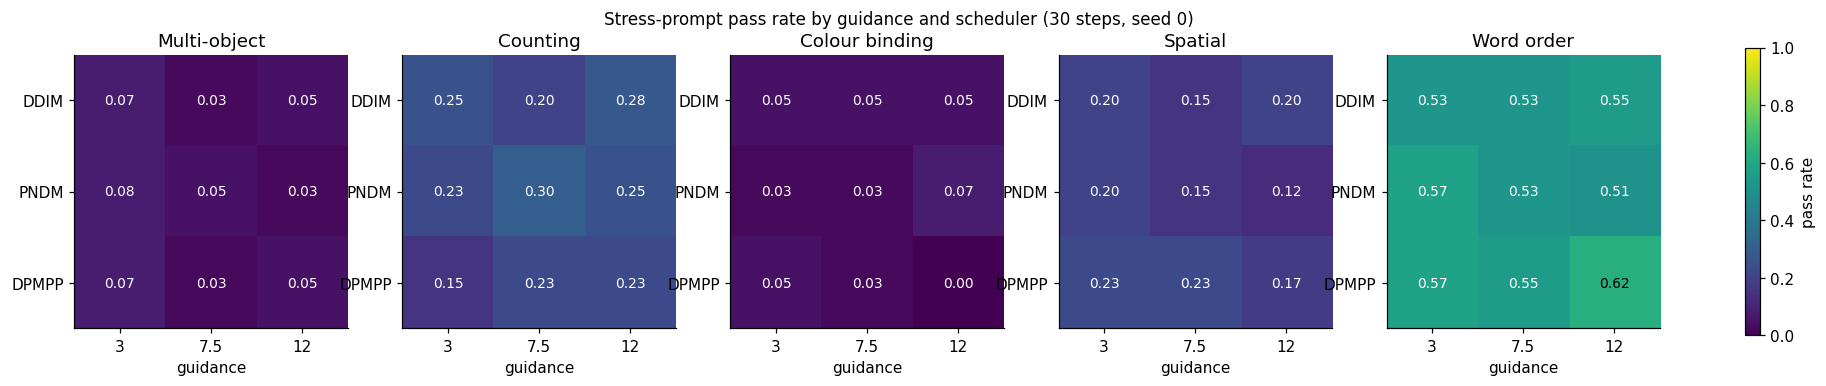

Effect of raising guidance from 3 to 12 (averaged over schedulers, 95% intervals):


,pass at guidance 3,pass at guidance 12,change,ci_lo,ci_hi
family,,,,,
Multi-object,0.075,0.042,-0.033,-0.100,0.025
Counting,0.208,0.250,0.042,-0.083,0.167
Colour binding,0.042,0.042,-0.000,-0.033,0.033
Spatial,0.208,0.167,-0.042,-0.125,0.033
Word order,0.558,0.567,0.008,-0.083,0.100



Seconds per image on Tesla T4 (30 steps; guidance does not change the work per step):


,mean,std,count
scheduler,,,
ddim,5.09,0.02,600
dpmpp,5.04,0.02,600
pndm,5.23,0.08,1000


In [10]:
sweep_scores = scores[scores.seed == CFG["sweep_seed"]]
sweep_scores = sweep_scores[sweep_scores.prompt_id.isin(sweep_prompts().prompt_id)]
grid = sweep_scores.groupby(["family", "scheduler", "guidance"])["pass"].mean().reset_index()
grid.to_csv(OUT / "sweep_by_family.csv", index=False)

fams = [f for f in FAMILIES if f in grid.family.unique()]
fig, axes = plt.subplots(1, len(fams), figsize=(4.0 * len(fams), 3.4), squeeze=False)
for ax, f in zip(axes[0], fams):
    m = grid[grid.family == f].pivot(index="scheduler", columns="guidance", values="pass").reindex(list(CFG["sweep_schedulers"]))
    im = ax.imshow(m.values, vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(m.shape[1])); ax.set_xticklabels([f"{g:g}" for g in m.columns])
    ax.set_yticks(range(m.shape[0])); ax.set_yticklabels([s.upper() for s in m.index])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.6 else "black", fontsize=9)
    ax.set(title=FAMILY_LABEL[f], xlabel="guidance")
plt.colorbar(im, ax=axes[0].tolist(), fraction=0.02, label="pass rate")
plt.suptitle(f"Stress-prompt pass rate by guidance and scheduler ({CFG['steps']} steps, seed {CFG['sweep_seed']})", fontsize=11)
savefig("02_sweep_heatmaps"); plt.show()

# guidance effect per family (averaged over schedulers), with paired intervals low vs high guidance
gl, gh = min(CFG["sweep_guidance"]), max(CFG["sweep_guidance"])
effects = []
for f in fams:
    s = sweep_scores[sweep_scores.family == f]
    lo = s[s.guidance == gl].groupby("prompt_id")["pass"].mean()
    hi = s[s.guidance == gh].groupby("prompt_id")["pass"].mean()
    d = (hi - lo).dropna()
    ci = bootstrap_ci(d.values)
    effects.append({"family": FAMILY_LABEL[f], f"pass at guidance {gl:g}": lo.mean(), f"pass at guidance {gh:g}": hi.mean(),
                    "change": ci["mean"], "ci_lo": ci["lo"], "ci_hi": ci["hi"]})
effects = pd.DataFrame(effects).set_index("family")
effects.to_csv(OUT / "guidance_effect.csv")
print(f"Effect of raising guidance from {gl:g} to {gh:g} (averaged over schedulers, 95% intervals):")
display(effects.round(3))

speed = gen_log[gen_log.setting.isin(SWEEP or [BASE])].groupby("scheduler")["seconds"].agg(["mean", "std", "count"])
speed.to_csv(OUT / "seconds_per_image.csv")
print(f"\nSeconds per image on {GPU} ({CFG['steps']} steps; guidance does not change the work per step):")
display(speed.round(2))

## 9. Samples and the generation log

For the Milestone 2 report: one passing and one failing image per family at the baseline (seed 0), saved with their prompts and verdicts in `samples/`, and the full **generation log** (every image with its prompt, seed, guidance, scheduler, steps, seconds and safety flag).

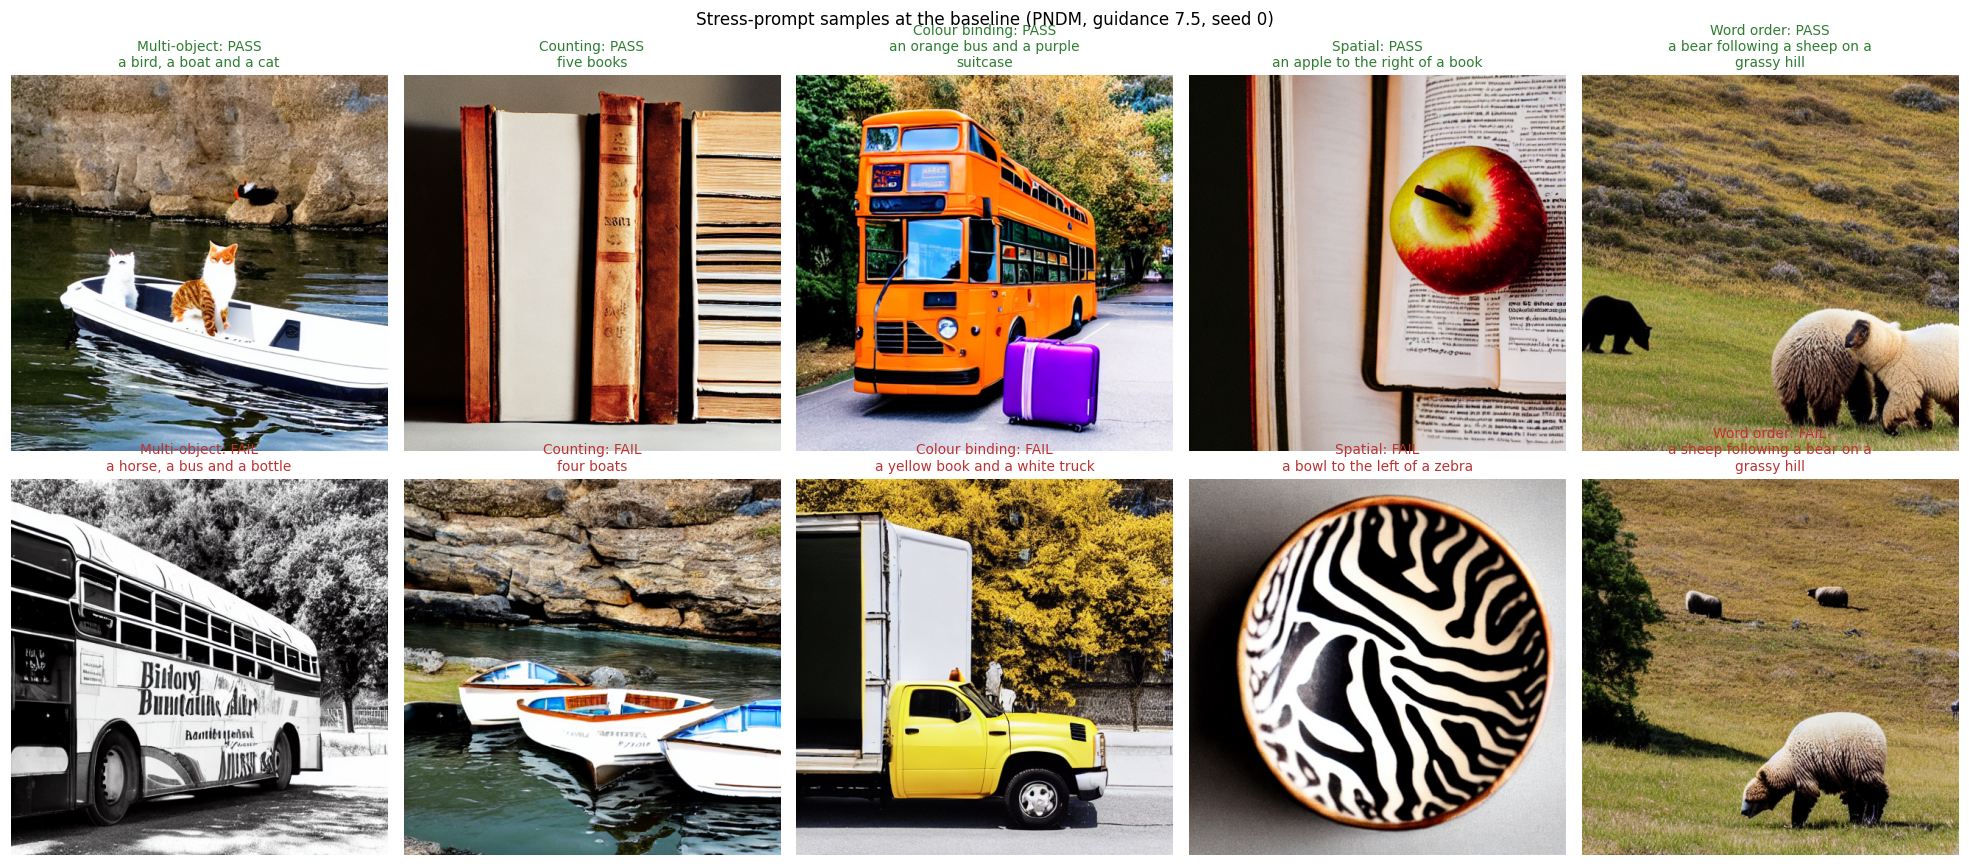

10 samples in /content/drive/MyDrive/w2w_praniti/results/m2_exp3/samples; generation log: 2200 images -> /content/drive/MyDrive/w2w_praniti/results/m2_exp3/generation_log.csv


In [11]:
picks = []
for f in FAMILIES:
    s = base_scores[(base_scores.family == f) & (base_scores.seed == 0)].sort_values("prompt_id")
    for verdict in (1.0, 0.0):
        hit = s[s["pass"] == verdict]
        if len(hit):
            picks.append((f, verdict, hit.iloc[0]))
fig, ax = plt.subplots(2, len(FAMILIES), figsize=(3.6 * len(FAMILIES), 8))
for j, f in enumerate(FAMILIES):
    for i, verdict in enumerate((1.0, 0.0)):
        a = ax[i, j]; a.axis("off")
        sel = [p for p in picks if p[0] == f and p[1] == verdict]
        if not sel:
            continue
        r = sel[0][2]
        path = gen_log[(gen_log.setting == BASE) & (gen_log.prompt_id == r.prompt_id) & (gen_log.seed == 0)].path.item()
        a.imshow(Image.open(path))
        prompt = stress.loc[stress.prompt_id == r.prompt_id, "prompt"].item()
        a.set_title(f"{FAMILY_LABEL[f]}: {'PASS' if verdict else 'FAIL'}\n" + textwrap.fill(prompt, 32), fontsize=9,
                    color="#2e7d32" if verdict else "#b33")
plt.suptitle("Stress-prompt samples at the baseline (PNDM, guidance 7.5, seed 0)", fontsize=11)
plt.tight_layout(); savefig("03_samples_pass_fail"); plt.show()

sample_rows = []
for f, verdict, r in picks:
    src = gen_log[(gen_log.setting == BASE) & (gen_log.prompt_id == r.prompt_id) & (gen_log.seed == 0)].path.item()
    dst = SAMPLES / f"{r.prompt_id}_{'pass' if verdict else 'fail'}.png"
    Image.open(src).save(dst)
    sample_rows.append({"file": dst.name, "family": FAMILY_LABEL[f], "prompt": stress.loc[stress.prompt_id == r.prompt_id, "prompt"].item(),
                        "verdict": "pass" if verdict else "fail", "seed": 0, "guidance": CFG["base_guidance"],
                        "scheduler": CFG["base_scheduler"], "steps": CFG["steps"]})
pd.DataFrame(sample_rows).to_csv(SAMPLES / "samples.csv", index=False)
gen_log.to_csv(LOG_FILE, index=False)
print(f"{len(sample_rows)} samples in {SAMPLES}; generation log: {len(gen_log)} images -> {LOG_FILE}")

## 10. Observations for the 1-page summary

The facts below are printed straight from the results, ready to turn into the Milestone 2 summary paragraph.

In [15]:
facts = []
bt = base_table.sort_values("pass rate", ascending=False)
facts.append("Baseline pass rates (PNDM, guidance 7.5, 3 seeds): " +
             "; ".join(f"{k} {v['pass rate']:.0%} ({v.ci_lo:.0%}-{v.ci_hi:.0%})" for k, v in bt.iterrows()))
facts.append(f"Best skill: {bt.index[0]}; worst: {bt.index[-1]}.")
facts += extra_lines
for fam, r in effects.iterrows():
    if r.ci_lo > 0:
        word = "improves"
    elif r.ci_hi < 0:
        word = "gets worse"
    else:
        word = "shows no detectable change"
    facts.append(f"Raising guidance {gl:g} -> {gh:g}: {fam} {word} ({r.change:+.0%}, 95% range {r.ci_lo:+.0%} to {r.ci_hi:+.0%}).")
best = grid.loc[grid.groupby("family")["pass"].idxmax()]
facts.append("Best setting per skill: " + "; ".join(f"{FAMILY_LABEL[r['family']]} {r['scheduler'].upper()} g{r['guidance']:g} ({r['pass']:.0%})" for idx, r in best.iterrows()))
facts.append("Seconds per image: " + ", ".join(f"{k.upper()} {v:.1f} s" for k, v in speed["mean"].items()) + f" on {GPU}.")
facts.append(f"Images generated: {len(gen_log)}; blacked out by the safety checker: {int(gen_log.blacked_out.sum())} (left out).")
print("\n".join("- " + f for f in facts))
open(OUT / "observations.txt", "w").write("\n".join(facts))

- Baseline pass rates (PNDM, guidance 7.5, 3 seeds): Word order 52% (39%-65%); Counting 29% (21%-38%); Spatial 21% (13%-29%); Multi-object 13% (7%-20%); Colour binding 3% (1%-7%)
- Best skill: Word order; worst: Colour binding.
- counting: right number 29%, off by at most one 64%, object present at all 98%
- colour binding verdicts: missing 75%, other 17%, swapped 5%, correct 3%
- Raising guidance 3 -> 12: Multi-object shows no detectable change (-3%, 95% range -10% to +2%).
- Raising guidance 3 -> 12: Counting shows no detectable change (+4%, 95% range -8% to +17%).
- Raising guidance 3 -> 12: Colour binding shows no detectable change (-0%, 95% range -3% to +3%).
- Raising guidance 3 -> 12: Spatial shows no detectable change (-4%, 95% range -12% to +3%).
- Raising guidance 3 -> 12: Word order shows no detectable change (+1%, 95% range -8% to +10%).
- Best setting per skill: Colour binding PNDM g12 (8%); Counting PNDM g7.5 (30%); Multi-object PNDM g3 (8%); Spatial DPMPP g3 (22%); Word 

1142

## 11. Milestone 1 follow-up: the text-encoder comparison, with intervals and a fixed word-order test

Two changes to the Milestone 1 encoder comparison, on the same 2,000 test captions:

1. **95% bootstrap intervals** on paraphrase retrieval and scene clustering, so differences between encoders can be judged.
2. **A word-order and colour test that measures meaning.** In Milestone 1 the "same meaning" sentence moved a whole phrase, which changed the sentence's structure more than the meaning-changing swap did. Now the same-meaning version keeps the structure and changes one word for a synonym:

| | Original | Same meaning (synonym) | Meaning changed (same words) |
|---|---|---|---|
| Word order | a bear following a sheep on a grassy hill | a bear trailing a sheep on a grassy hill | a sheep following a bear on a grassy hill |
| Colour | a yellow book and a white truck | a yellow book along with a white truck | a white book and a yellow truck |

An encoder passes if the synonym version is closer than the swapped version. A word-count model (TF-IDF) now scores **0%**: the swapped sentence has exactly the same words, the synonym one does not. Passing requires understanding who does what and which colour goes where.

In [16]:
SYN = {"chasing": "running after", "looking at": "watching", "standing next to": "standing beside",
       "following": "trailing", "sitting behind": "seated behind"}


def fixed_triplets():
    order, colour = [], []
    wo = stress[stress.family == "word_order"]
    for pid, g in wo.groupby("pair_id"):
        r0, r1 = g.iloc[0], g.iloc[1]
        v = r0.expected_d["verb"]
        order.append((r0.prompt, r0.prompt.replace(f" {v} ", f" {SYN[v]} "), r1.prompt))
    for r in stress[stress.family == "colour_binding"].itertuples():
        a, b = r.objects_l
        ca, cb = r.expected_d["colour"][a], r.expected_d["colour"][b]
        colour.append((r.prompt, r.prompt.replace(" and ", " along with ", 1),
                       f"{article(cb)} {cb} {a} and {article(ca)} {ca} {b}"))
    return order, colour


ORDER3, COLOUR3 = fixed_triplets()
for o, same, changed in ORDER3 + COLOUR3:
    assert sorted(o.split()) == sorted(changed.split()) and same != o
print(ORDER3[0]); print(COLOUR3[0])

('a bear following a sheep on a grassy hill', 'a bear trailing a sheep on a grassy hill', 'a sheep following a bear on a grassy hill')
('a yellow book and a white truck', 'a yellow book along with a white truck', 'a white book and a yellow truck')


In [17]:
if CFG["run_encoder_polish"]:
    from transformers import AutoModel, AutoTokenizer, CLIPTextModel, CLIPTokenizer, T5EncoderModel
    from sklearn.feature_extraction.text import TfidfVectorizer

    ENC = {"CLIP ViT-L/14": "sd_text_encoder", "BERT-base": "google-bert/bert-base-uncased",
           "T5-base": "google-t5/t5-base", "GPT-2": "openai-community/gpt2"}

    def load_enc(ref):
        if ref == "sd_text_encoder":
            return (CLIPTokenizer.from_pretrained(CFG["sd_id"], subfolder="tokenizer"),
                    CLIPTextModel.from_pretrained(CFG["sd_id"], subfolder="text_encoder").to(DEVICE).eval())
        tok = AutoTokenizer.from_pretrained(ref)
        model = (T5EncoderModel if "t5" in ref else AutoModel).from_pretrained(ref).to(DEVICE).eval()
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        return tok, model

    @torch.no_grad()
    def embed(tok, model, ref, texts, batch=64):
        sent, eos = [], []
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), padding=True, truncation=True, max_length=77, return_tensors="pt",
                      return_special_tokens_mask=True)
            special = enc.pop("special_tokens_mask").to(DEVICE)
            enc = {k: v.to(DEVICE) for k, v in enc.items()}
            out = model(**enc)
            keep = (enc["attention_mask"].bool() & ~special.bool()).float().unsqueeze(-1)
            sent.append(((out.last_hidden_state.float() * keep).sum(1) / keep.sum(1).clamp(min=1)).cpu().numpy())
            if ref == "sd_text_encoder":
                eos.append(out.pooler_output.float().cpu().numpy())
        return np.concatenate(sent), (np.concatenate(eos) if eos else None)

    other = caps[caps.image_id.isin(ev.image_id) & ~caps.caption_idx.isin(ev.caption_idx)]
    para = other.groupby("image_id").first().reindex(ev.image_id).caption.tolist()
    cat_super = {c["id"]: c["supercategory"] for c in inst_json["categories"]}
    largest = {}
    for a in inst_json["annotations"]:
        if a["image_id"] not in largest or a["area"] > largest[a["image_id"]][0]:
            largest[a["image_id"]] = (a["area"], cat_super[a["category_id"]])
    scene = np.array([largest.get(i, (0, "none"))[1] for i in ev.image_id])

    texts = {"captions": ev.caption.tolist(), "paraphrases": para}
    for fam, trip in (("order", ORDER3), ("colour", COLOUR3)):
        for j, part in enumerate(("orig", "same", "changed")):
            texts[f"{fam}_{part}"] = [t[j] for t in trip]
    EMB = defaultdict(dict)
    for name, ref in ENC.items():
        tok, model = load_enc(ref)
        for key, tx in texts.items():
            s, e = embed(tok, model, ref, tx)
            EMB[name][key] = s
            if e is not None:
                EMB["CLIP (EOS)"][key] = e
        del model; torch.cuda.empty_cache()
    tfidf = TfidfVectorizer(token_pattern=r"[a-zA-Z]+").fit(caps.caption.tolist() + sum(texts.values(), []))
    for key, tx in texts.items():
        EMB["TF-IDF words"][key] = tfidf.transform(tx).toarray().astype(np.float32)
    REPS = ["CLIP (EOS)", "CLIP ViT-L/14", "T5-base", "BERT-base", "GPT-2", "TF-IDF words"]

    def l2n(x):
        return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-8, None)

    def triplet_pass(o, s, c):
        o, s, c = l2n(o), l2n(s), l2n(c)
        return ((o * s).sum(1) > (o * c).sum(1)).astype(float)

    rows = []
    for r in REPS:
        q, g = l2n(EMB[r]["captions"]), l2n(EMB[r]["paraphrases"])
        sims = q @ g.T
        hit1 = ((sims > np.diag(sims)[:, None]).sum(1) < 1).astype(float)
        s2 = q @ q.T; np.fill_diagonal(s2, -np.inf)
        nn = np.argsort(-s2, axis=1)[:, :10]
        knn_ok = np.array([Counter(scene[row]).most_common(1)[0][0] == scene[i] for i, row in enumerate(nn)], dtype=float)
        ret, knn = bootstrap_ci(hit1), bootstrap_ci(knn_ok)
        wo = bootstrap_ci(triplet_pass(EMB[r]["order_orig"], EMB[r]["order_same"], EMB[r]["order_changed"]))
        co = bootstrap_ci(triplet_pass(EMB[r]["colour_orig"], EMB[r]["colour_same"], EMB[r]["colour_changed"]))
        rows.append({"encoder": r, "paraphrase R@1": ret["mean"], "R@1 95%": f"{ret['lo']:.3f}-{ret['hi']:.3f}",
                     "scene 10-NN": knn["mean"], "10-NN 95%": f"{knn['lo']:.3f}-{knn['hi']:.3f}",
                     "word order (fixed)": wo["mean"], "word order 95%": f"{wo['lo']:.2f}-{wo['hi']:.2f}",
                     "colour (fixed)": co["mean"], "colour 95%": f"{co['lo']:.2f}-{co['hi']:.2f}"})
    enc_table = pd.DataFrame(rows).set_index("encoder")
    enc_table.to_csv(OUT / "encoder_comparison_with_intervals.csv")
    display(enc_table.round(3))
    print("Word-order / colour: pass = the synonym version is closer than the swapped version. "
          "TF-IDF scores 0 by construction; 50% would be a coin flip.")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (15 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

,paraphrase R@1,R@1 95%,scene 10-NN,10-NN 95%,word order (fixed),word order 95%,colour (fixed),colour 95%
encoder,,,,,,,,
CLIP (EOS),0.340,0.319-0.360,0.745,0.726-0.763,0.40,0.20-0.60,0.725,0.57-0.85
CLIP ViT-L/14,0.214,0.196-0.233,0.700,0.679-0.720,1.00,1.00-1.00,1.000,1.00-1.00
T5-base,0.154,0.139-0.171,0.684,0.664-0.705,0.20,0.05-0.40,0.025,0.00-0.07
BERT-base,0.130,0.115-0.145,0.658,0.637-0.678,0.05,0.00-0.15,0.000,0.00-0.00
GPT-2,0.034,0.026-0.042,0.560,0.538-0.582,0.30,0.10-0.50,0.250,0.12-0.40
TF-IDF words,0.198,0.181-0.215,0.643,0.622-0.664,0.00,0.00-0.00,0.000,0.00-0.00


Word-order / colour: pass = the synonym version is closer than the swapped version. TF-IDF scores 0 by construction; 50% would be a coin flip.


## 12. Summary

In [18]:
summary = {"config": CFG, "gpu": GPU,
           "images": {"total": int(len(gen_log)), "blacked_out": int(gen_log.blacked_out.sum()),
                      "by_setting": gen_log.groupby("setting").size().to_dict()},
           "baseline_by_family": base_table.round(4).to_dict("index"),
           "sweep_by_family": grid.round(4).to_dict("records"),
           "guidance_effect": effects.round(4).to_dict("index"),
           "seconds_per_image": speed["mean"].round(3).to_dict(),
           "observations": facts}
if CFG["run_split_fix"]:
    summary["split_fix"] = split_fix
if CFG["run_encoder_polish"]:
    summary["encoder_comparison"] = enc_table.round(4).to_dict("index")
json.dump(summary, open(OUT / "m2_exp3_summary.json", "w"), indent=2, default=str)
print("saved to", OUT)
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT))

saved to /content/drive/MyDrive/w2w_praniti/results/m2_exp3
   baseline_by_family.csv
   config.json
   encoder_comparison_with_intervals.csv
   figures/01_baseline_by_family.png
   figures/02_sweep_heatmaps.png
   figures/03_samples_pass_fail.png
   generation_log.csv
   guidance_effect.csv
   m2_exp3_summary.json
   observations.txt
   samples/colour_binding_00_fail.png
   samples/colour_binding_31_pass.png
   samples/counting_00_fail.png
   samples/counting_03_pass.png
   samples/multi_object_00_fail.png
   samples/multi_object_17_pass.png
   samples/samples.csv
   samples/spatial_00_fail.png
   samples/spatial_02_pass.png
   samples/word_order_00_pass.png
   samples/word_order_01_fail.png
   scores.csv
   seconds_per_image.csv
   splits/real_ref_2000_disjoint.csv
   sweep_by_family.csv
